# Exercise 5: Machine Translation with Transformers

In this exercise, you will explore the Transformer-based neural architecture by tackling a machine translation task. Machine translation involves translating text from a source language to a target language. Traditionally, machine translation was performed using recurrent neural network (RNN)-based architectures. However, the emergence of Transformers has marked a revolutionary shift in the fields of text analysis and especially machine translation.

Transformers offer several advantages over earlier RNN-based models for the machine translation task:

* One major benefit is their ability to capture context from a long sequence using self-attention layers, which allows the model to retain relevant information from words further back in the text.
  
* Additionally, Transformers improve the natural flow and grammatical accuracy of translated sentences. Unlike RNN models, which tend to follow the word order of the source language, Transformers utilize cross-attention layers between the source and target languages. This allows them to arrange translated words in an order that sounds more natural in the target language, even if it differs significantly from the source structure.
  
* Finally, Transformers enable parallelization, which makes it feasible to train them on multiple GPUs, speeding up the training process. 


To complete this assignment, you will progress through four different stages (tasks):

**Task 1. Data Preparation (5 points)**

**Task 2. Model Architecture (5 points)**

**Task 3. Training and Evaluation (5 points)**

**Task 4. Autoregressive Translation (5 points)**

### **Deliverables**

Submit to Moodle, without renaming them:

* `ex5.ipynb`, the completed notebook
* `model.pth`, your trained model (Task 3)

You do not need to submit the data or `ex5_helpers.py`.

### **Data**

The data comes with this notebook: the folder `dataset_ex5`, next to `ex5.ipynb`, holds two CSV files with 137,860 short sentences each:

    small_vocab_fr.csv: French sentences.
    small_vocab_en.csv: Corresponding English translations.

If you keep the folder somewhere else, set `path` below to it. Check for an extra folder level after unzipping. During grading, the autograder reads its own copy of the same files.

### **Useful links**

* https://pytorch.org/docs/stable/generated/torch.nn.Transformer.html
* https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html

### **Notes**

1. Remove the line `raise NotImplementedError()` from every cell where you write your code.
2. `skip_training` is used for grading: you may change its value in the cell where it is defined, but do not set it anywhere else in the notebook. Set it to `True` to run the notebook without training: the notebook then loads your saved `model.pth` before Task 4.
3. Keep `ex5_helpers.py` in the same folder as this notebook: the tests use it. You do not need to read it.
4. Do not delete cells. The cells that say "Do not delete this cell" hold tests that run after you submit.
5. The figures of this notebook show each task on an example sentence, with the values of a trained model. If a figure does not show in your editor, open it in the folder `figures` next to this notebook.

After setting up the folders, you are ready to begin the exercise tasks. Let's get started!

In [ ]:
skip_training = False   # True: run the notebook without training; Task 4 then uses your saved model.pth

In [ ]:
# Do not delete this cell

Set `path` to the folder that contains the two CSV files. The folder `dataset_ex5` comes with this notebook.

In [ ]:
path = "dataset_ex5"   # change it if you keep the data somewhere else

In [ ]:
# Do not delete this cell

Import all necessary libraries.

In [ ]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")    # on Windows, prevents the kernel crash "OMP: Error #15"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import random_split
import torch.nn.functional as F
import torch.optim as optim

import warnings
warnings.filterwarnings("ignore")

# Set random seeds for all libraries
import random
random.seed(1)
np.random.seed(1)
torch.manual_seed(1)
torch.cuda.manual_seed(1)
torch.cuda.manual_seed_all(1)

# Ensure deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

try:
    from ex5_helpers import start_grading, training_allowed
except ImportError:
    raise ImportError('ex5_helpers.py was not found: keep it in the same folder as this notebook.') from None
AUTOGRADING = start_grading(globals().get('autograding', False))    # True only while the autograder grades the notebook

Select the device

In [ ]:
if torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if AUTOGRADING:
    device = torch.device('cpu')    # grading runs on the CPU
print(device)

## Task 1: Data Preparation (5 Points)

In this task, you will preprocess the dataset to convert it into a format suitable for input to a Transformer neural model. Each subtask focuses on a specific step in the preprocessing pipeline.

### Summary of Tasks for This Stage

**Task 1.1: Tokenization** (1 point)

**Task 1.2: Building Vocabulary** (1 point)

**Task 1.3: Sentence Embedding** (1 point)

**Task 1.4: Positional Encoding** (2 points)

The figure shows the whole of Task 1 on one sentence: the tokens, their ids, the embedding and the positional encoding give the matrix that goes into the Transformer.

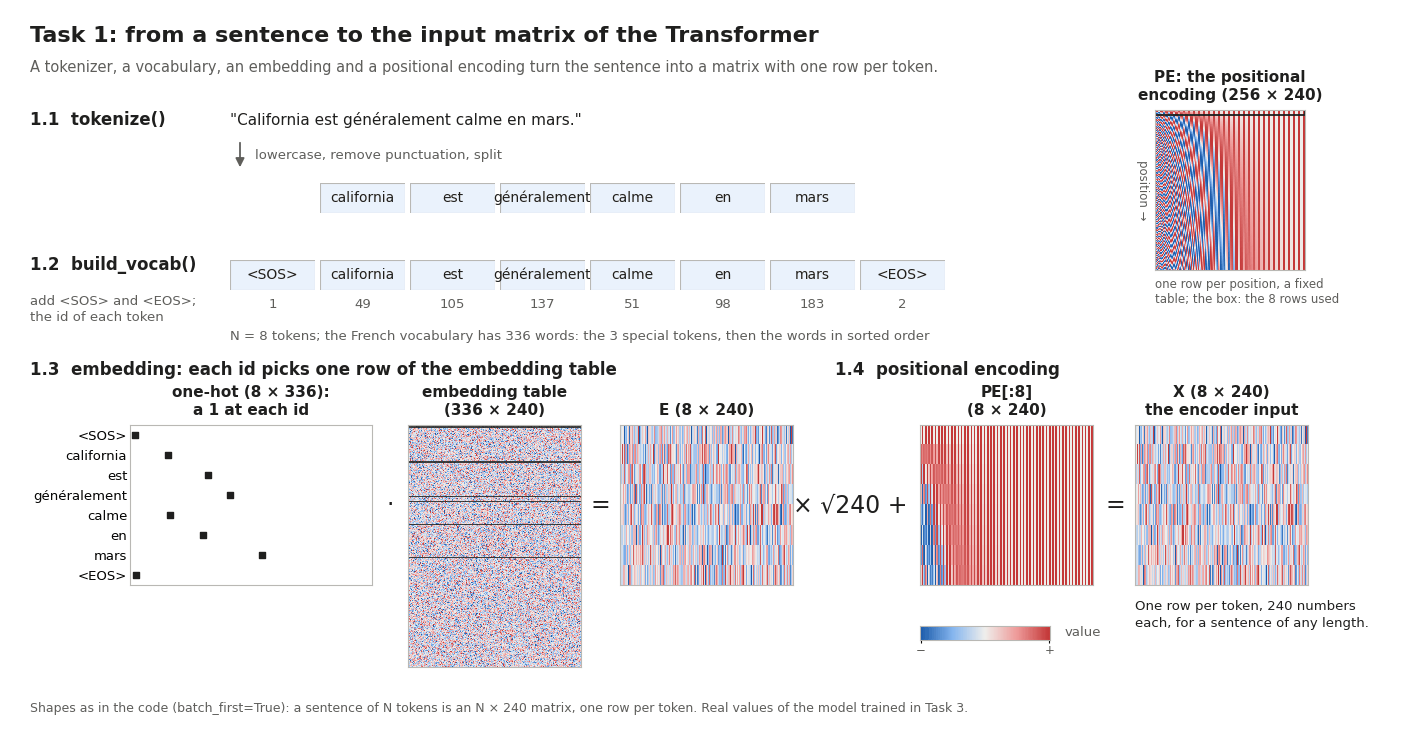

### Task 1.1: Tokenization

In this task, we use a basic tokenization method for simplicity and to avoid potential library mismatch issues that could arise across different students' systems and environments. While more advanced tokenization methods are available through specialized libraries, this basic approach ensures consistency and focuses on the core concept of tokenization. Our method uses Python's built-in tools and includes the following steps: 

1. Lowercasing: Convert all characters in the sentence to lowercase.
2. Filtering Characters: Define a set of characters to be removed from the sentences, replacing them with an empty string.
3. Splitting: Split the sentence into tokens based on spaces.
   
Run the cell below to load the data, observe basic statistics, and examine some sample sentences.

In [ ]:
# Load your data. During grading, the autograder reads its own copy of the same files.
from ex5_helpers import data_folder
folder = data_folder(globals().get('path', 'dataset_ex5'), globals().get('TA_data_path'), AUTOGRADING)
en_df = pd.read_csv(os.path.join(folder, 'small_vocab_en.csv'), header=None, usecols=[0])
fr_df = pd.read_csv(os.path.join(folder, 'small_vocab_fr.csv'), header=None, usecols=[0])

english_sentences = en_df[0].values
french_sentences = fr_df[0].values

print(f'There are {len(english_sentences)} English sentences in data')
print(f'There are {len(french_sentences)} French sentences in data')
print('Here are some examples:')
e = [ 0, 1000, 3000]
for i in e:
    print(10*"-")
    print(english_sentences[i])
    print(french_sentences[i])
print(100*"_")

Complete the "tokenize" function by filling in the blanks based on the detailed guidance provided within the code comments. 

In [ ]:
# Tokenize function 
def tokenize(sentences):
    """
    Tokenizes a list of sentences by:
    1. Converting all text to lowercase.
    2. Removing special characters listed in "filters".
    Hint: you can use "str.maketrans" to creates a translation table to remove unwanted characters defined in "filters".
    3. Splitting each sentence into a list of words.
    """
    filters = '.?!#$%&()*+,-/:;<=>@«»""[\\]^_`{|}~\t\n'
    
    # YOUR CODE HERE
    raise NotImplementedError()
    
    return tokenized_list
    
# Tokenize English and French sentences
tokenized_en = tokenize(english_sentences)
tokenized_fr = tokenize(french_sentences)
for i in e:
    print(10*"-")
    print(tokenized_en[i])
    print(tokenized_fr[i])

Run the cell below to check the correctness of your solution to the tokenize function.

In [ ]:
# Visible test of tokenize()
from ex5_helpers import run_test, check_tokenize
run_test('Task 1.1: tokenize() (visible test)', lambda: check_tokenize(tokenize))

### Task 1.2: Building Vocabulary

In this step, we will convert tokenized sentences into lists of integers. This is achieved by defining a dictionary of unique words for each language and assigning a unique integer to each word.

You may recall practicing a similar concept in Exercise 4, where you built a character-based dictionary. In this exercise, we are building a word-level dictionary, where each entry in the dictionary represents a unique word.

In addition to the set of unique words in the dataset, the vocabulary must include three special tokens:

1.  PAD: Padding Token (0)
2.  SOS: Start of Sentence (1)
3.  EOS: End of Sentence (2)

After the special tokens come the words of the data in sorted (alphabetical) order, so that the vocabulary is the same every time you run the notebook. The order of a Python `set` changes every time Python starts: a model saved in one session would not fit the vocabulary of the next one, nor the vocabulary used at grading.

Complete the "build_vocab" function by filling in the blanks according to the provided instructions in the code.

In [ ]:
# Create vocabulary with special tokens
def build_vocab(tokenized_sentences):
    special_tokens = ["<PAD>", "<SOS>", "<EOS>"]
    # build vocab by applying "Counter" for sentence in tokenized_sentences and for token in sentence
    # add special tokens, then the words in sorted order
    # word2idx = ? (a dictionary for mapping word to index)
    # idx2word = ? (a dictionary for index to word)
    
    # YOUR CODE HERE
    raise NotImplementedError()
    
    return word2idx, idx2word

en_word2idx, en_idx2word = build_vocab(tokenized_en)
fr_word2idx, fr_idx2word = build_vocab(tokenized_fr)

print("Here are some examples from our English dictionary: ")
print(100 * "-")

# Display first 10 words and their indices from en_word2idx
for i, (key, value) in enumerate(en_word2idx.items()):
    print(f'word: {key}, index: {value}')
    if i == 9:  # After 10 iterations, break
        break

print(10 * "_")

# Display first 10 indices and their words from en_idx2word
for i, (key, value) in enumerate(en_idx2word.items()):
    print(f'index: {key}, word: {value}')
    if i == 9:  # After 10 iterations, break
        break

Run the cell below to check the correctness of your solution to the build_vocab function.

In [ ]:
# Visible test of build_vocab()
from ex5_helpers import run_test, check_vocab
run_test('Task 1.2: build_vocab() (visible test)', lambda: check_vocab(build_vocab))

### Dataset Class

In this step, we will use a custom dataset class specifically designed for our translation task. You do not need to implement anything for this step, as the dataset class is already provided for you. This class incorporates essential preprocessing steps, such as padding, truncation, and the addition of special tokens.

As discussed earlier, sentences in our dataset have varying lengths. To ensure all sentences are of the same length (a requirement for the Transformer model), we will define a fixed length for input sequences. The preprocessing steps performed by the dataset class include:

* Special Tokens: The 'SOS' token is added at the beginning of each sentence, and the 'EOS' token is added at the end.
* Truncation: Sentences that exceed the defined maximum length will be truncated to fit the specified length.
* Padding: The 'PAD' token is appended to sentences shorter than the maximum length until they reach the required length.

Take some time to go through the dataset class and its methods to observe how these preprocessing steps are implemented. Understanding the class structure will help you in tasks where you might need to customize or extend the dataset functionality.


In [ ]:
# Dataset class with padding applied in __getitem__
class TranslationDataset(Dataset):
    def __init__(self, src_sentences, tgt_sentences, src_vocab, tgt_vocab, seq_len=30):
        self.src_sentences = src_sentences
        self.tgt_sentences = tgt_sentences
        self.src_vocab = src_vocab
        self.tgt_vocab = tgt_vocab
        self.seq_len = seq_len

    def __len__(self):
        return len(self.src_sentences)

    def pad_sequence(self, tokens, vocab, is_target=False):
        """
        Pads a sequence of tokens to the fixed length `seq_len`.
        Adds <SOS> at the start, <EOS> at the end, and pads with <PAD>.
        Trims if the sequence is longer than `seq_len`.
        """
        tokens = [vocab["<SOS>"]] + [vocab.get(token, vocab["<PAD>"]) for token in tokens]
        tokens.append(vocab["<EOS>"])  
        tokens = tokens[:self.seq_len]  
        tokens += [vocab["<PAD>"]] * (self.seq_len - len(tokens))  
        return tokens

    def __getitem__(self, idx):
        
        src_tokens = self.src_sentences[idx]
        tgt_tokens = self.tgt_sentences[idx]
        
        # Apply padding to both the source and target sentences
        src_padded = self.pad_sequence(src_tokens, self.src_vocab, is_target=False)
        tgt_padded = self.pad_sequence(tgt_tokens, self.tgt_vocab, is_target=True)
        
        # Convert to tensors and move to device (GPU or CPU)
        src_item = torch.tensor(src_padded).to(device)
        tgt_item = torch.tensor(tgt_padded).to(device)
    
        return src_item, tgt_item

# Instantiate and test the dataset, let the French be as source language and English as target language.
dataset = TranslationDataset(tokenized_fr, tokenized_en, fr_word2idx, en_word2idx,  seq_len=10)
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

# Test the DataLoader
for src_batch, tgt_batch in dataloader:
    print("Source batch:", src_batch)
    print(src_batch.size())
    print(10*"_")
    print("Target batch:", tgt_batch)
    print(tgt_batch.size())
    print(10*"_")
    break

### Task 1.3: Sentence Embedding

Words, by themselves, are discrete symbols that neural networks cannot process directly. To make them understandable to the model, we use **embedding layers**. These layers transform words or tokens into dense, fixed-size vectors, where each word is represented by a unique vector. The embedding layer maps words into a continuous vector space, enabling semantically similar words to be closer to each other in this space. This approach is far more compact and efficient than sparse, high-dimensional representations like one-hot encoding.

Embedding layers are particularly useful in natural language processing tasks such as **machine translation**, where words in different languages must be represented in a way that enables the model to learn their relationships.

In this step, you are asked to define separate PyTorch embedding layers for both the source and target languages, and then pass the src_batch and tgt_batch through these layers. In the cell below, complete the code by filling in the blanks according to the provided instructions. After running the cell, pay attention to the input and output dimensions of the embedding layers.


In [ ]:
embedding_size = 128
vsize_src = len(fr_word2idx)
vsize_tgt = len(en_word2idx)

# data: let the French be as source language and English as target language.
dataset = TranslationDataset(tokenized_fr, tokenized_en, fr_word2idx, en_word2idx,  seq_len=10)
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

# Use 'next' to get a batch from the DataLoader iterator
src_batch, tgt_batch = next(iter(dataloader))

# embedding_fr = ? (define an embedding layer for French words in your French Vocabulary)
# embedding_fr.to(device)
# output_embedding_fr = ? (pass src_batch through embedding_fr)

# embedding_en = ? (define an embedding layer for English words in your English Vocabulary)
# embedding_en.to(device)
# output_embedding_en = ? 

# YOUR CODE HERE
raise NotImplementedError()

print(10*"_")
print(src_batch.size())
print(output_embedding_fr.size())
print(10*"_")
print(tgt_batch.size())
print(output_embedding_en.size())

Run the cell below to check the correctness of your solution for the sentence embedding.

In [ ]:
# Visible test of the embedding shapes (0 points)
from ex5_helpers import run_test, check_embedding_shapes
run_test('Task 1.3: embedding shapes (visible test, 0 points)',
         lambda: check_embedding_shapes(output_embedding_fr, output_embedding_en, src_batch, tgt_batch, embedding_size))

In [ ]:
# Do not delete this cell. It contains hidden tests that are run after submission.

### Task 1.4: Positional encoding

In sequence models like the Transformer, the model needs a way to understand the relative positions of words in a sequence. Since the Transformer model does not inherently process sequential data in a time-dependent manner (unlike RNNs or LSTMs), we need to explicitly provide information about the position of each word in the input sequence.

The Positional Encoding layer is used to add this positional information to the word embeddings. It generates a vector for each position in the sequence and combines it with the word embedding to provide both the content and position information. The positional encoding is computed using sine and cosine functions of different wavelengths, which allows the model to easily learn relative positions.

In this step, your task is to implement the Positional Encoding layer. You should:

1. Compute the positional encodings using sine and cosine functions.
2. Register the positional encodings as a buffer so they are not considered trainable parameters.
3. Add the positional encoding to the word embeddings during the forward pass.

Once you have implemented the layer, you can test if it works correctly by running the test cell.


In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, embed_size, max_len=512):
        super(PositionalEncoding, self).__init__()
        self.embed_size = embed_size
        
        # Initialize a tensor to store positional encodings for each position up to max_len
        pos_encoding = torch.zeros(max_len, embed_size)
        # Create a tensor for positions, where each position corresponds to a word's position in the sequence
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        
        # 1. Create a tensor `div_term` to scale the positional encoding values. 
        
        # Hint:
        # This is based on the formula for positional encoding where each dimension has a different frequency.
        # We generate a range of values from 0 to embed_size, stepping by 2 (for even indices), and multiply it by a scaling factor.
        # The scaling factor (-math.log(10000.0) / embed_size) ensures the frequencies decay logarithmically.
        
        # 2. Apply the sine function to the even indices of the positional encoding matrix.
        # 3. Apply the cosine function to the odd indices of the positional encoding matrix.
        
        # Hint:
        # The `position` tensor holds the position values for each token, and `div_term` scales those values.
        
        # YOUR CODE HERE
        raise NotImplementedError()
        
        # Register as buffer so it is not considered as a parameter during training
        self.register_buffer('pos_encoding', pos_encoding.unsqueeze(0))

    def forward(self, x):
        # Add positional encoding to embeddings
        x = x * math.sqrt(self.embed_size)
        x = x + self.pos_encoding[:, :x.size(1), :].to(x.device)
        return x

In [ ]:
#%% Applying positional encoding 
positional_encoding = PositionalEncoding(embedding_size, 512)
output_pe_fr = positional_encoding (output_embedding_fr)
output_pe_en = positional_encoding (output_embedding_en)
print(10*"_")
print(output_pe_fr.size())
print(output_pe_en.size())

In [ ]:
# Visible test of the positional encoding
from ex5_helpers import run_test, check_positional_encoding
run_test('Task 1.4: positional encoding (visible test)', lambda: check_positional_encoding(PositionalEncoding))

## Task 2: Model Architecture (5 points)

### Summary of Tasks for This Stage

**Task 2.1: Designing a basic transformer block** (3 points)

**Task 2.2: Adding Encoder and Decoder blocks** (2 points)

The heart of the model is self-attention. The figure shows it in matrix form for one sentence, and why the same weights work for a sentence of any length.

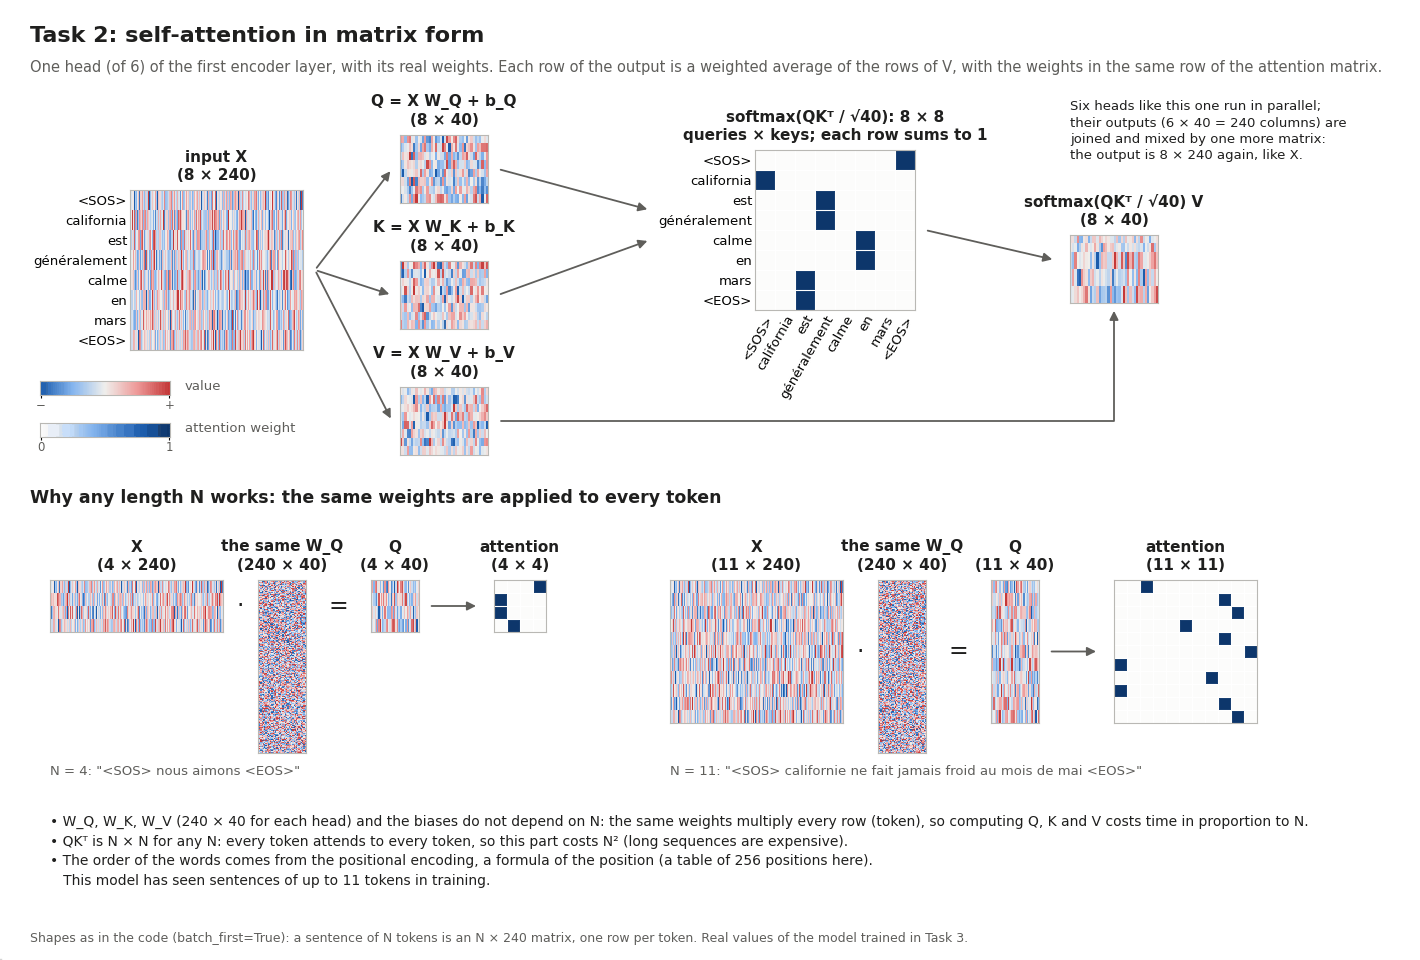

### Task 2.1: Designing a basic transformer block

In this task, you will implement a simple Transformer model. This model will take source and target sequences as input, apply embeddings and positional encodings, pass the result through a Transformer block, and finally project the output to the target vocabulary space. Before passing the input through the Transformer block, you need to compute two types of masks:

**Padding Mask:** This mask is applied to the source sequence and to the target sequence to prevent the model from attending to padding tokens, which should be ignored during training. The padding mask is implemented in the create_pad_mask method. The source padding mask is needed twice: as `src_key_padding_mask`, so that the encoder ignores the padded source positions, and as `memory_key_padding_mask`, so that the decoder ignores them too when it attends to the encoder output. Without the second, the decoder reads the padded positions, and the model learns to depend on them: its translations then change with the padding.

**Target Mask (tgt_mask):** This mask is used to prevent the model from using future target steps to predict the current output. If the model could access future information, it would already know the solution, making training redundant. The tgt_mask helps ensure causal attention by masking out future tokens in the target sequence.

These two masks are essential for enabling effective training and maintaining the correct flow of information through the model.

The figure shows the masks of this task on example sentences: a mask adds −∞ to the attention scores of the positions that must not be seen.

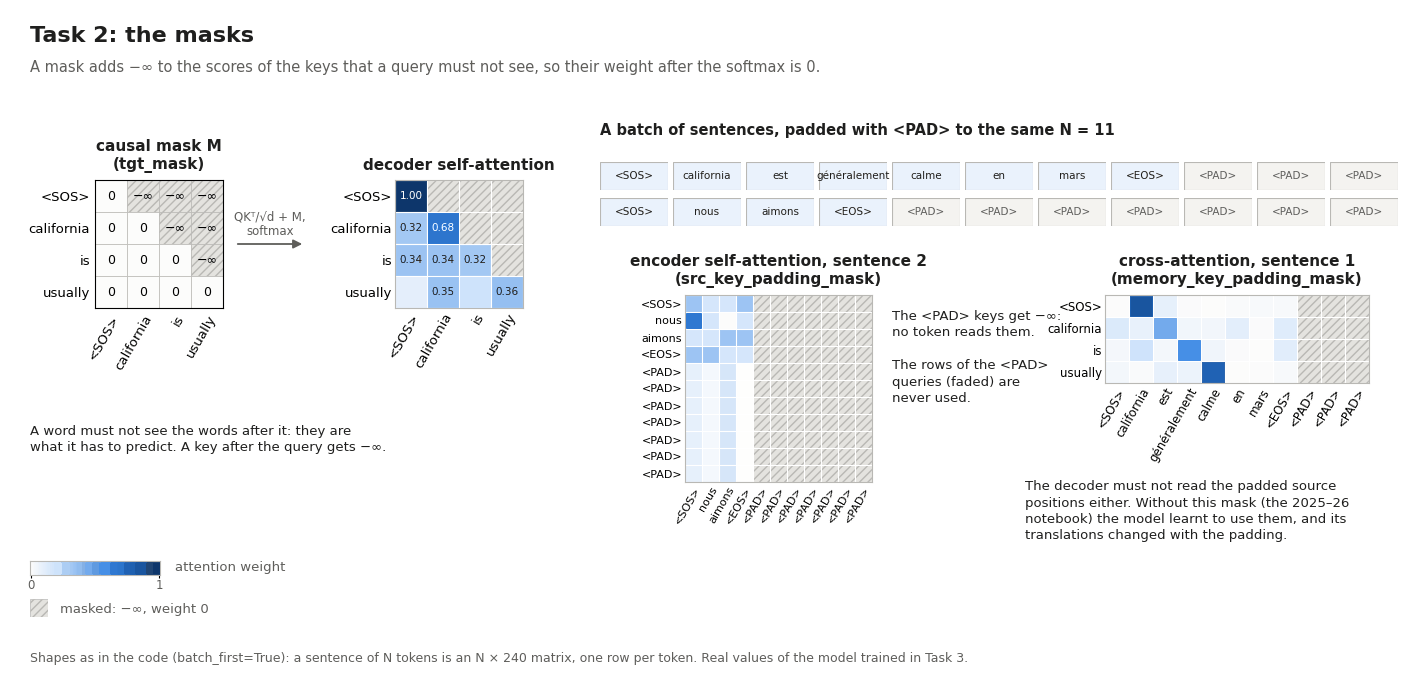

For this task, you can use the pre-implemented embedding and positional encoding blocks. In the MySimpleTransformer template provided below, fill in the blanks as instructed in the code. Once you have implemented the MySimpleTransformer class, you can test the correctness of your solution by running the test cell. The test builds the model with vocabularies of 336 French and 201 English words and runs it on two random sentences: it checks the shape of the output, the number of parameters, that the positional encoding is used, that no position of the output depends on later target tokens (the causal mask), and that the output does not depend on how much padding the source has (the memory padding mask).

You may receive a warning about using 'batch_first' during the initialization of the Transformer block. Please ignore it!

In [ ]:
class MySimpleTransformer(nn.Module):
    def __init__(self, vocab_size_src, vocab_size_tgt, embed_size, num_heads, hidden_dim, num_encoder_layers, num_decoder_layers, max_len=512):
        super(MySimpleTransformer, self).__init__()
        # Initialize layers as below:
        # Embedding layer for source language tokens
        # embedding layer for target language tokens
        # Positional encoding
        # Transformer block (Hint: use nn.Transformer)
        # Final linear layer to project transformer output to vocab size (Hint: use nn.Linear)
        
        # YOUR CODE HERE
        raise NotImplementedError()
        
    def forward(self, src, tgt, src_padding_mask=None, tgt_padding_mask=None, tgt_mask=None):
        
        # 1. Get embeddings for source and target.
        # 2. apply positional encoding to embedded source and target
        # 3. Create a causal mask for the target to prevent seeing future tokens
        # 4. Forward pass to Transformer block with the masks: the source padding mask as src_key_padding_mask and
        #    as memory_key_padding_mask (so that the decoder ignores the padded source positions too), the target
        #    padding mask as tgt_key_padding_mask, and tgt_mask
        # 5. Project to vocabulary size
            
        # YOUR CODE HERE
        raise NotImplementedError()

        return output
    
    def get_tgt_mask(self, tgt):
        tgt_seq_len = tgt.size(1)
        tgt_mask = self.transformer.generate_square_subsequent_mask(tgt_seq_len).to(tgt.device)
        return tgt_mask
    
    def create_pad_mask(self, matrix):
        # If matrix = [1,2,3,0,0,0] where pad_token=0, the result mask is
        # [False, False, False, True, True, True]
        pad_token = 0
        return (matrix == pad_token)

def get_num_trainable_parameters(model):
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'The model has {num_params} trainable parameters.')
    return num_params

In [ ]:
# Visible test of MySimpleTransformer
from ex5_helpers import run_test, check_transformer
run_test('Task 2.1: MySimpleTransformer (visible test)', lambda: check_transformer(MySimpleTransformer, PositionalEncoding))

In [ ]:
# The masks of one example sentence pair
example_dataset = TranslationDataset(tokenized_fr, tokenized_en, fr_word2idx, en_word2idx, seq_len=10)
src_batch, tgt_batch = (t.unsqueeze(0) for t in example_dataset[0])
example_model = MySimpleTransformer(len(fr_word2idx), len(en_word2idx), 512, 2, 128, 3, 3, max_len=512)
src_padding_mask = example_model.create_pad_mask(src_batch)
tgt_mask = example_model.get_tgt_mask(tgt_batch)

print(src_batch.size())
print(tgt_batch.size())

print(src_padding_mask.size())
print(src_batch.cpu().detach().numpy())
print(src_padding_mask.cpu().detach().numpy())

print(tgt_mask.size())
print(tgt_mask.cpu().detach().numpy())

### Task 2.2: Adding Encoder and Decoder blocks

The MySimpleTransformer class you implemented uses the Transformer module of PyTorch, which consists of two main parts: the encoder and the decoder. Each part of the model contains several layers of self-attention and feedforward neural networks, with the encoder and decoder connected by a cross-attention mechanism.

**Self-Attention:** In the context of machine translation, self-attention allows each word in a sequence (either in the source or target language) to attend to every other word in the same sequence, regardless of their position. This mechanism enables the model to capture long-range dependencies and relationships within the sentence.

**Cross-Attention:** This occurs in the decoder block, where the model attends to the encoder's output. In machine translation, cross-attention allows the decoder to focus on relevant parts of the input sequence (source language) when generating the output sequence (target language). It essentially "crosses" between the encoder and decoder, enabling the model to translate based on the context of both source and target sentences.

Next, we will modify our Transformer block by manually separating the encoder and decoder components. This separation is necessary because, during inference (translation), the source sentence must pass through the encoder, and the generated target sentence must pass through the decoder one token at a time. This step is crucial since the translation process is autoregressive, meaning each word is predicted based on the previously generated words.

In the cell below, complete the MyTransformer class as an updated version of our model class. This updated version will be used to train our neural machine translation system. Ensure that the encoder and decoder components are implemented separately, as this is important for managing the inference process later.

Hints:

1. The updated model is similar to the simple model from Task 2.1, except that the encoder and decoder are separated to allow individual calls. Remember to include the source and target padding masks, as well as the target causal mask (tgt_mask).

2. The layer initialization for the updated model should be identical to the simple model. Specifically, the *init* method of the MyTransformer class should mirror the MySimpleTransformer class.

3. Use nn.Transformer.encoder(src_embedded, src_key_padding_mask=src_padding_mask)

4. Use nn.Transformer.decoder(tgt_embedded, memory, tgt_mask=tgt_mask, tgt_key_padding_mask=tgt_padding_mask, memory_key_padding_mask=memory_padding_mask). `memory_padding_mask` is the source padding mask: the decoder must not attend to the padded source positions either. `forward()` passes `src_padding_mask` to `decode()` for it.

Once you have implemented the MyTransformer class, you can test the correctness of your solution by running the test cell.


In [ ]:
class MyTransformer(nn.Module):
    def __init__(self, vocab_size_src, vocab_size_tgt, embed_size, num_heads, hidden_dim, num_encoder_layers, num_decoder_layers, max_len=512):
        super(MyTransformer, self).__init__()
        # Initialize layers similar to MySimpleTransformer
        # Two Embedding layers for source and target text
        # Positional encoding
        # Transformer block
        # Final linear layer to project transformer output to vocab size
        
        # YOUR CODE HERE
        raise NotImplementedError()
    
    def encode(self, src, src_padding_mask):
        # 1. Get embeddings for source 
        # 2. apply positional encoding to embedded source 
        # 3. Forward pass to Transformer encoder block with src_key_padding_mask
        
        # YOUR CODE HERE
        raise NotImplementedError()
        
        return encoded

    def decode(self, tgt, memory, tgt_mask, tgt_padding_mask, memory_padding_mask=None):
        # 1. Get embeddings for target
        # 2. apply positional encoding to embedded target
        # 3. Forward pass target and memory (output of encode) to Transformer decoder block with tgt_mask,
        #    tgt_key_padding_mask and memory_key_padding_mask (memory_padding_mask: the source padding mask)
        
        # YOUR CODE HERE
        raise NotImplementedError()
        
        return decoded

    def forward(self, src, tgt, src_padding_mask=None, tgt_padding_mask=None, tgt_mask=None):
        # 1. pass source through encode block (name it as memory)
        # 2. pass target and memory through decode block, with src_padding_mask as memory_padding_mask
        # 3. Project to vocabulary size  
        
        # YOUR CODE HERE
        raise NotImplementedError()
        
        return  output_decoder, output 
    
    def get_tgt_mask(self, tgt):
        tgt_seq_len = tgt.size(1)
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(tgt_seq_len).to(tgt.device)
        return tgt_mask
    
    def create_pad_mask(self, matrix):
        # If matrix = [1,2,3,0,0,0] where pad_token=0, the result mask is
        # [False, False, False, True, True, True]
        pad_token = 0
        return (matrix == pad_token)

In [ ]:
# Visible test of MyTransformer
from ex5_helpers import run_test, check_transformer
run_test('Task 2.2: MyTransformer (visible test)', lambda: check_transformer(MyTransformer, PositionalEncoding, separate=True))

## Task 3: Training and Validation (5 points)

So far, we have defined our dataset class and the Transformer model. The next step is to train and validate the model. We will split the data into training and validation sets, with an 80% training and 20% validation ratio, and run the training and validation loops accordingly.

For the model, we will define a simple Transformer with a hidden dimension of 512, 4 encoder layers, 4 decoder layers, and 6 attention heads. We will use cross-entropy loss, which is well-suited for Transformer-based machine translation because it measures the difference between the predicted probability distribution and the true distribution for each token in the sequence. This loss function helps the model optimize the prediction accuracy for each word in the target sequence. Additionally, we will use the Adam optimizer to efficiently minimize the loss. 

First, run the two cells below to define the data and model with the specified hyperparameters.

In [ ]:
# Data

bs = 256
dataset = TranslationDataset(tokenized_fr, tokenized_en, fr_word2idx, en_word2idx,  seq_len=11)
number_of_sentences = len(tokenized_fr)
train_size = int((0.8)*number_of_sentences)
test_size = int(number_of_sentences - train_size)
train_dataset, test_dataset = random_split(dataset, [train_size, test_size], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True, drop_last=True)
val_loader = DataLoader(test_dataset, batch_size=bs, shuffle=False, drop_last=True)
print(f'Training samples: {len(train_dataset)}, Validation samples: {len(test_dataset)}')

In [ ]:
# Model

embedding_size = 240 # embed_dim must be divisible by num_heads
vsize_src = len(fr_word2idx) # 336 
vsize_tgt = len(en_word2idx) # 201
hdim = 512
model = MyTransformer(vsize_src, vsize_tgt, embedding_size, 6, hdim, 4, 4, max_len=256)
model = model.to(device)

In the cell below, complete the training and validation loops by filling in the blanks as instructed in the code. Then run the cell to train the model.

Train for three epochs (`num_epochs = 3`): the validation loss is then usually about 0.04, and the translations are good. One epoch takes under a minute on a GPU and 5 to 20 minutes on a laptop CPU. More epochs do no harm.

After every epoch in which the validation loss is the lowest so far, the cell saves the model to **model.pth**, so `model.pth` holds your best epoch. Submit it to Moodle with your notebook.

The figure shows what the training loop computes for one sentence, and the loss of a model trained for 10 epochs.

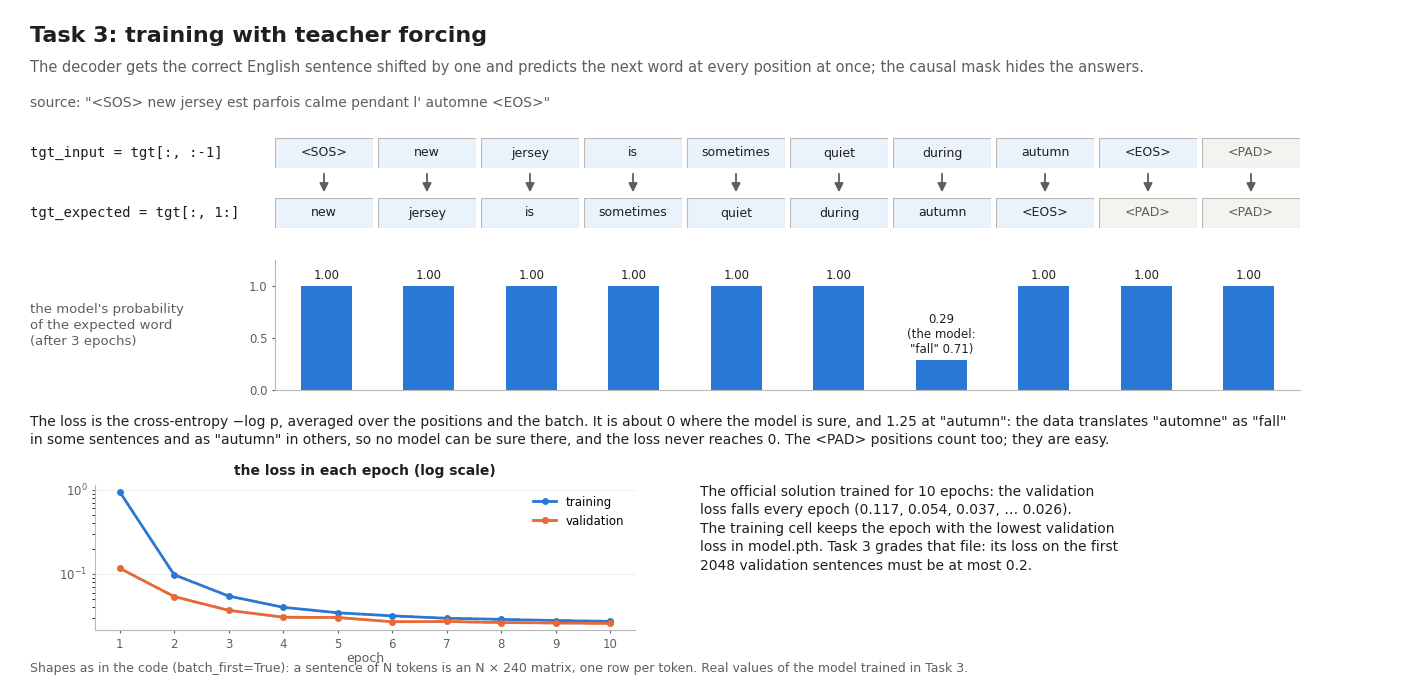

**How Task 3 is graded:** the hidden test loads your submitted `model.pth` into `MyTransformer` with the settings of the cell above (do not change them) and computes its validation loss as the validation loop does: it must be at most 0.2. The test uses the first 2048 validation sentences, so that it runs in a few seconds. The cell after the training cell computes the same number, so you can check it before you submit.

In [ ]:
# Training 
criterion = nn.CrossEntropyLoss()  
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9)
num_epochs =3

if training_allowed(skip_training):    # never during grading
    epoch_train_losses = []
    epoch_validation_losses = []
    best_validation_loss = float("inf")
    for epoch in range(num_epochs):
        model = model.to(device)
        model.train()  # Set model to training mode
        total_loss = 0
        num_samples = 0
        for src_batch, tgt_batch in train_loader:
            optimizer.zero_grad()
            # set input source as src_batch
            # set input target as start of target sentence until -1 (i.e. discard the last token) (past) [name it as tgt_input]
            # set expected target as target sentence from 1 to the end (i.e. discard the first token) (future) [name it as tgt_expected]
            # use input source and input target (tgt_input) as input to the model
            # expected target will be used in loss to compare it with the model output.
            # Remember to use padding and target causal masks on the model call:
            # get padding mask of source,
            # get padding mask of input target, convert it to float (.float()),
            # get tgt_mask of input target,
            # pass input source, input target, source padding mask, and tgt_mask to the model to get the predictions (output).
            
            # YOUR CODE HERE
            raise NotImplementedError()
            
            output = output.to(device)
            output = output.contiguous().view(-1, vsize_tgt)
            tgt_expected = tgt_expected.contiguous().view(-1)    
            
            loss = criterion(output, tgt_expected)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
            num_samples += src_batch.shape[0]
    
        epoch_train_loss = total_loss / len(train_loader)
        epoch_train_loss = round(epoch_train_loss, 4)
        epoch_train_losses.append(epoch_train_loss)
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {epoch_train_loss}")
        
        ################################################################
        
        model.eval()
        validation_loss = 0
        num_samples = 0
        with torch.no_grad():
            for src_batch, tgt_batch in val_loader:
                # set input source as src_batch
                # set input target as start of target sentence until -1 (i.e. discard the last token) (past) [name it as tgt_input]
                # set expected target as target sentence from 1 to the end (i.e. discard the first token) (future) [name it as tgt_expected]
                # use input source and input target (tgt_input) as input to the model
                # expected target will be used in loss to compare it with the model output.
                # Remember to use padding and target causal masks on the model call:
                # get padding mask of source,
                # get padding mask of input target, convert it to float (.float()),
                # get tgt_mask of input target,
                # pass input source, input target, source padding mask, and tgt_mask to the model to get the predictions (output).
                    
                # YOUR CODE HERE
                raise NotImplementedError()
                
                output = output.to(device)
                output = output.contiguous().view(-1, vsize_tgt)
                tgt_expected = tgt_expected.contiguous().view(-1)  
                loss = criterion(output, tgt_expected)
                validation_loss += loss.item()
                num_samples += src_batch.shape[0]
                
            epoch_validation_loss = validation_loss / len(val_loader)
            epoch_validation_loss = round(epoch_validation_loss, 4)
            epoch_validation_losses.append(epoch_validation_loss)
            
        print(f"Epoch {epoch + 1}/{num_epochs}, Validation Loss: {epoch_validation_loss}")
        if epoch_validation_loss < best_validation_loss:    # keep the model of the epoch with the lowest validation loss
            best_validation_loss = epoch_validation_loss
            torch.save(model.state_dict(), 'model.pth')
            print(f"Saved the model to model.pth (validation loss {epoch_validation_loss})")

    print("Training completed.")
    
    plt.figure(figsize=(10, 6))
    epochs = range(1, num_epochs + 1)
    plt.plot(epochs, epoch_train_losses, label='Train Loss', color='blue', marker='o')
    plt.plot(epochs, epoch_validation_losses, label='Validation Loss', color='red', marker='x')
    plt.title('Train vs Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
# Visible check of Task 3 (0 points). This cell loads your saved model.pth into model, so that Task 4 translates
# with it (during grading: the model.pth you submitted). Then it computes the validation loss of model.pth on the first
# 2048 validation sentences, as the hidden test of Task 3 does: it must be at most 0.2.
from ex5_helpers import run_test, load_trained_model, saved_model_loss, loss_message, LOSS_LIMIT

print(load_trained_model(model, device, AUTOGRADING))


def test_saved_model_visible():
    loss = saved_model_loss(MyTransformer, tokenized_fr, tokenized_en, fr_word2idx, en_word2idx, device)
    assert loss <= LOSS_LIMIT, loss_message(loss, fr_word2idx, en_word2idx, advice='Train for more epochs.')
    print(f'The validation loss of your saved model.pth (on the first 2048 validation sentences) is {loss}: at most '
          f'{LOSS_LIMIT} is needed.')


if not AUTOGRADING:    # during grading, the hidden test below computes it
    run_test('Task 3: the validation loss of your saved model.pth (visible check, 0 points)', test_saved_model_visible)

In [ ]:
# Do not delete this cell. It contains hidden tests that are run after submission.

## Task 4: Autoregressive Translation (5 points)

Finally, we are going to use the trained model to perform an actual translation task, translating French sentences into English. Exciting!

The inference works in an autoregressive manner. This means that, during the translation process, the model generates each token in the target sequence one at a time, using the previously generated token as input for predicting the next one. At each step, the model uses the encoded source sentence along with the target sequence generated so far to predict the next word. This approach allows the model to produce the translation step by step, instead of generating the entire sequence at once.

The steps for translation are as follows:

**Source Sentence Encoding:** First, we obtain the source sequence embedding and pass it through the encoder to obtain its encoded representation.

**Initializing Target Sentence with <SOS> Token:** We initialize the target sentence with the special <SOS> (Start Of Sentence) token, which indicates the beginning of the translation.

**Autoregressive Loop to Translate Target Tokens One at a Time:** We enter a loop where the model predicts the next token in the sequence based on the previously generated token and the encoded source sentence. This loop continues until the model predicts the <EOS> (End Of Sentence) token or the maximum sequence length is reached.

The figure shows the loop on the example sentence of the cell below.

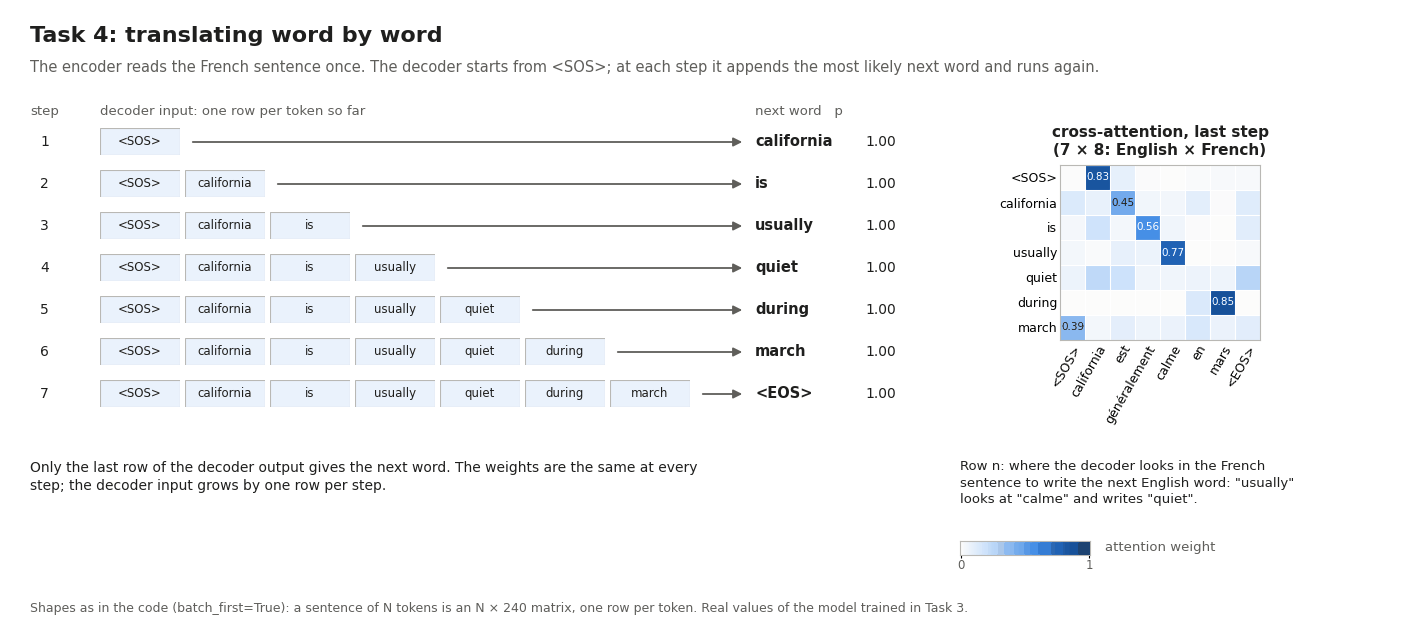

In the cell below, fill in the blanks as instructed to create the translation loop for the provided example sentences. Once you have completed the template, run it and observe the printed translation results. 

During grading, this cell runs again with your submitted `model.pth`, and the hidden test checks every word of both translations: each must be the most likely next word according to the model, and the translation must stop when `<EOS>` is generated.

In [ ]:
seq_len=10
start_token=1
end_token=2
model.eval()  

# Convert src_sentence to tokenized integers in the vocabulary dictionary 
example_source_sentences = ["new jersey est parfois calme pendant l' automne.", "california est généralement calme en mars."]
example_tokenized = tokenize(example_source_sentences)
src_sentences = []
for ex in example_tokenized:
    ex_inds = [start_token]    # as in training: <SOS>, the words, <EOS>
    for t in ex:
        if t in fr_word2idx:    # a word that is not in the vocabulary is left out
            ex_inds.append(fr_word2idx[t])
    ex_inds.append(end_token)
    src_sentences.append(ex_inds)    

translated_sequences = []
for counter, src_sentence in enumerate(src_sentences):    
    # Convert source tokens to Tensor 
    src_tensor = torch.tensor(src_sentence, dtype=torch.long).unsqueeze(0).to(device)  # Shape: (1, src_seq_length)
    
    # 1. create src_padding_mask
    # 2. get "memory" by passing source with create src_padding_mask through encode block (model.encode)
    
    # YOUR CODE HERE
    raise NotImplementedError()
    
    # initialize the predicted tgt_tokens (translation) with start token
    tgt_tokens = torch.ones(1, 1).fill_(start_token).type(torch.long).to(device) #(1,1)

    for i in range(seq_len-1):
        # 1. Mask out the unpredicted tokens in the target (i.e., get tgt_mask)
        # 2. get output by passing target (the generated part up to current `i`) and memory to decode block (model.decode),
        #    with src_padding_mask as memory_padding_mask
        # 3. remember to pass also tgt_mask
        # 4. get a probability vector by passing output through linear layer (projection to vocabulary size)
        # 5. use "torch.max" to get the index of the predicted word
        # 6. Convert it to a tensor on device (name it as "next_tgt_item")
        # 7. add "next_tgt_item" to tgt_tokens (use torch.cat)
        # 8. Stop (break) if "end_token" is generated
        
        # YOUR CODE HERE
        raise NotImplementedError()
    
    translated_tokens = tgt_tokens.squeeze().tolist()
    translated_sentence = ' '.join ([en_idx2word[i] for i in translated_tokens[1:]])
    translated_sequences.append(translated_tokens)
    print("original_sentence:", example_source_sentences[counter])
    print("translated_sentence:", translated_sentence)
    print(10*'-')

In [ ]:
# Do not delete this cell. It contains hidden tests that are run after submission.

In [ ]:
# Do not delete this cell